# <center>**Netflix Top 10 Viewership Analysis**

### Project Overview

Analyzed Netflix Top 10 viewing data from July 2021 through April 2024, including global weekly rankings, country-level rankings across 94 countries, and Netflix's most popular titles, to examine whether a title's longevity in the Top 10 offers more insight into audience engagement than its initial popularity.

## **Data Preparation and Exploration**

In [1]:
# Import Packages, ignore warnings, and print inline

import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
# Load in the datasets and show the first few rows

df_countries = pd.read_excel('all-weeks-countries-netflix.xlsx')
df_global = pd.read_excel('all-weeks-global-netflix.xlsx')
df_popular = pd.read_excel('most-popular-netflix.xlsx')

display(df_countries.head(5))
display(df_global.head(5))
display(df_popular.head(5))

,country_name,country_iso2,week,category,weekly_rank,show_title,season_title,cumulative_weeks_in_top_10
0,Argentina,AR,2024-04-14,Films,1,The Tearsmith,NaN,2
1,Argentina,AR,2024-04-14,Films,2,Stolen,NaN,1
2,Argentina,AR,2024-04-14,Films,3,"Love, Divided",NaN,1
3,Argentina,AR,2024-04-14,Films,4,Woody Woodpecker Goes to Camp,NaN,1
4,Argentina,AR,2024-04-14,Films,5,Rest In Peace,NaN,3


,week,category,weekly_rank,show_title,season_title,weekly_hours_viewed,runtime,weekly_views,cumulative_weeks_in_top_10,is_staggered_launch,episode_launch_details
0,2024-04-14,Films (English),1,What Jennifer Did,NaN,26100000,1.4500,18000000.0,1,False,NaN
1,2024-04-14,Films (English),2,Woody Woodpecker Goes to Camp,NaN,19600000,1.6667,11800000.0,1,False,NaN
2,2024-04-14,Films (English),3,Scoop,NaN,14600000,1.7167,8500000.0,2,False,NaN
3,2024-04-14,Films (English),4,Glass,NaN,11000000,2.1500,5100000.0,2,False,NaN
4,2024-04-14,Films (English),5,Megan Leavey,NaN,9700000,1.9333,5000000.0,1,False,NaN


,category,rank,show_title,season_title,hours_viewed_first_91_days,runtime,views_first_91_days
0,Films (English),1,Red Notice,NaN,454200000,1.9667,230900000
1,Films (English),2,Don't Look Up,NaN,408600000,2.3833,171400000
2,Films (English),3,The Adam Project,NaN,281000000,1.7833,157600000
3,Films (English),4,Bird Box,NaN,325300000,2.0667,157400000
4,Films (English),5,Leave the World Behind,NaN,339300000,2.3667,143400000


In [3]:
# Show the structure and columns of each dataset

print("COUNTRIES DATASET")
print(df_countries.info())
print("\nColumns:", df_countries.columns.tolist())

print("GLOBAL DATASET")
print(df_global.info())
print("\nColumns:", df_global.columns.tolist())

print("POPULAR DATASET")
print(df_popular.info())
print("\nColumns:", df_popular.columns.tolist())

COUNTRIES DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 272260 entries, 0 to 272259
Data columns (total 8 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   country_name                272260 non-null  object
 1   country_iso2                272260 non-null  object
 2   week                        272260 non-null  object
 3   category                    272260 non-null  object
 4   weekly_rank                 272260 non-null  int64 
 5   show_title                  272260 non-null  object
 6   season_title                131585 non-null  object
 7   cumulative_weeks_in_top_10  272260 non-null  int64 
dtypes: int64(2), object(6)
memory usage: 16.6+ MB
None

Columns: ['country_name', 'country_iso2', 'week', 'category', 'weekly_rank', 'show_title', 'season_title', 'cumulative_weeks_in_top_10']
GLOBAL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5840 entries, 0 to 5839
Data columns (total

In [4]:
# Get the summary statistics

print("COUNTRIES describe:")
display(df_countries.describe(include='all').transpose().head(10))

print("\nGLOBAL describe:")
display(df_global.describe(include='all').transpose().head(10))

print("\nPOPULAR describe:")
display(df_popular.describe(include='all').transpose().head(10))

COUNTRIES describe:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_name,272260,94,Argentina,2920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_iso2,272260,94,AR,2920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
week,272260,146,2021-10-10,1880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,272260,2,Films,136130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekly_rank,272260.0,NaN,NaN,NaN,5.5,2.872287,1.0,3.0,5.5,8.0,10.0
show_title,272260,7146,Stranger Things,3258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season_title,131585,2375,"Pablo Escobar, el patrón del mal: Season 1",1359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cumulative_weeks_in_top_10,272260.0,NaN,NaN,NaN,3.471913,6.572933,1.0,1.0,2.0,3.0,113.0



GLOBAL describe:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
week,5840,146,2024-04-14,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,5840,4,Films (English),1460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekly_rank,5840.0,NaN,NaN,NaN,5.5,2.872527,1.0,3.0,5.5,8.0,10.0
show_title,5840,1915,Manifest,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season_title,2814,835,"Yo soy Betty, la fea: Season 1",30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekly_hours_viewed,5840.0,NaN,NaN,NaN,18507143.835616,26460886.776938,700000.0,6330000.0,11470000.0,20567500.0,571760000.0
runtime,1760.0,NaN,NaN,NaN,3.613172,3.031191,0.0,1.6667,2.1667,5.2,20.3
weekly_views,1760.0,NaN,NaN,NaN,4545568.181818,5002303.359835,600000.0,1800000.0,3000000.0,5100000.0,50800000.0
cumulative_weeks_in_top_10,5840.0,NaN,NaN,NaN,3.08887,3.221536,1.0,1.0,2.0,4.0,30.0
is_staggered_launch,5840,2,False,5768,NaN,NaN,NaN,NaN,NaN,NaN,NaN



POPULAR describe:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
category,40,4,Films (English),10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rank,40.0,NaN,NaN,NaN,5.5,2.908872,1.0,3.0,5.5,8.0,10.0
show_title,40,35,Money Heist,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season_title,20,20,Wednesday: Season 1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hours_viewed_first_91_days,40.0,NaN,NaN,NaN,528400000.0,481368692.322961,86500000.0,237575000.0,355950000.0,711675000.0,2205200000.0
runtime,40.0,NaN,NaN,NaN,4.778338,3.234889,1.5333,1.9667,3.1333,7.000025,13.0667
views_first_91_days,40.0,NaN,NaN,NaN,110082500.0,52471588.83258,50900000.0,66575000.0,98850000.0,136625000.0,265200000.0


In [5]:
# Fix the date columns and confirm it was done

df_countries['week'] = pd.to_datetime(df_countries['week'])
df_global['week'] = pd.to_datetime(df_global['week'])

print("Countries dtypes:")
print(df_countries.dtypes)

print("\nGlobal dtypes:")
print(df_global.dtypes)

Countries dtypes:
country_name                          object
country_iso2                          object
week                          datetime64[ns]
category                              object
weekly_rank                            int64
show_title                            object
season_title                          object
cumulative_weeks_in_top_10             int64
dtype: object

Global dtypes:
week                          datetime64[ns]
category                              object
weekly_rank                            int64
show_title                            object
season_title                          object
weekly_hours_viewed                    int64
runtime                              float64
weekly_views                         float64
cumulative_weeks_in_top_10             int64
is_staggered_launch                     bool
episode_launch_details                object
dtype: object


In [6]:
# Check for missing values

print("COUNTRIES - Missing Values:")
print(df_countries.isna().sum())

print("\nGLOBAL - Missing Values:")
print(df_global.isna().sum())

print("\nPOPULAR - Missing Values:")
print(df_popular.isna().sum())

COUNTRIES - Missing Values:
country_name                       0
country_iso2                       0
week                               0
category                           0
weekly_rank                        0
show_title                         0
season_title                  140675
cumulative_weeks_in_top_10         0
dtype: int64

GLOBAL - Missing Values:
week                             0
category                         0
weekly_rank                      0
show_title                       0
season_title                  3026
weekly_hours_viewed              0
runtime                       4080
weekly_views                  4080
cumulative_weeks_in_top_10       0
is_staggered_launch              0
episode_launch_details        5768
dtype: int64

POPULAR - Missing Values:
category                       0
rank                           0
show_title                     0
season_title                  20
hours_viewed_first_91_days     0
runtime                        0
views_first_91

In [7]:
# Handle missing values

print("COUNTRIES missing values (kept, films may not be seasonal):")
print("\nGLOBAL missing values (runtime/views missing for some, will decide case-by-case):")

df_popular['season_title'] = df_popular['season_title'].fillna('Movie')
print("\nPOPULAR missing values (season_title missing for films, filled in with Movie):")
print(df_popular.isna().sum())

COUNTRIES missing values (kept, films may not be seasonal):

GLOBAL missing values (runtime/views missing for some, will decide case-by-case):

POPULAR missing values (season_title missing for films, filled in with Movie):
category                      0
rank                          0
show_title                    0
season_title                  0
hours_viewed_first_91_days    0
runtime                       0
views_first_91_days           0
dtype: int64


## VISUAL 1 - Overall Viewership in the Global Top 10

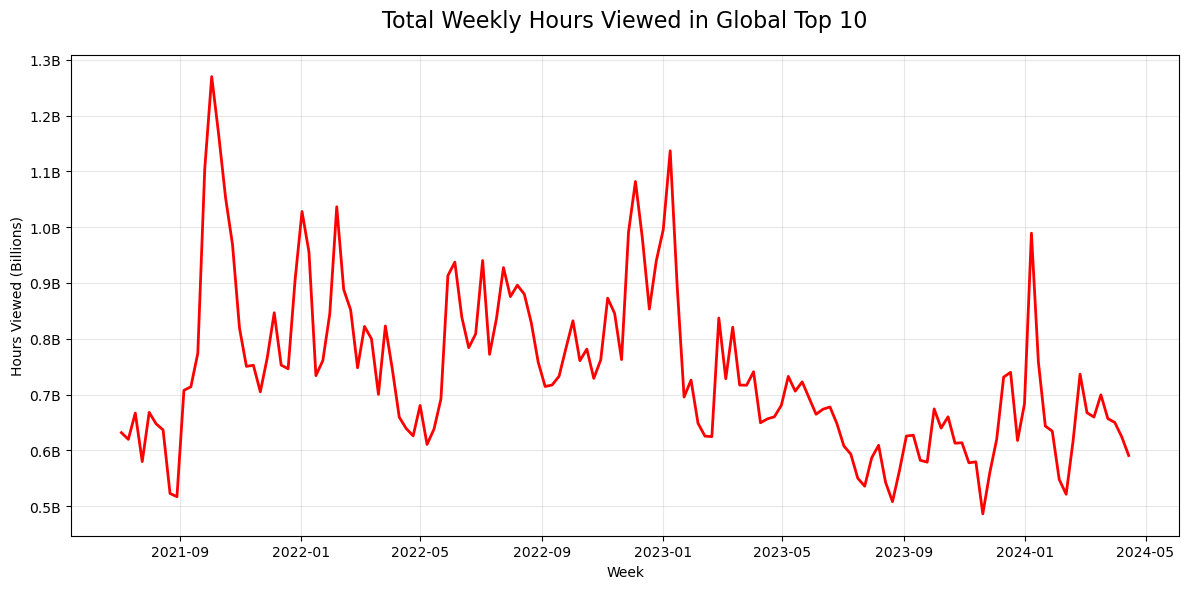

In [8]:
# Group by week and sum weekly hours viewed

global_trend = df_global.groupby('week')['weekly_hours_viewed'].sum().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(global_trend['week'], global_trend['weekly_hours_viewed'], color='red', linewidth=2)
plt.title('Total Weekly Hours Viewed in Global Top 10', fontsize=16, pad=20)
plt.xlabel('Week')
plt.ylabel('Hours Viewed (Billions)')
plt.gca().yaxis.set_major_formatter(lambda x, pos: f'{x/1e9:.1f}B') # Format y-axis in Billions
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## VISUAL 2 - Films vs. TV Shows in Global Viewership

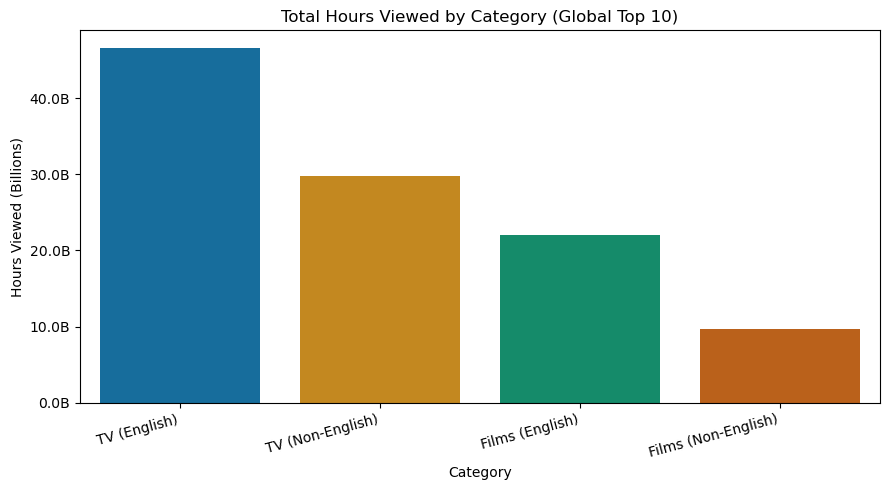

In [9]:
# Show total hours by category across all weeks

cat_hours = (df_global.groupby("category", as_index=False)["weekly_hours_viewed"].sum()
             .sort_values("weekly_hours_viewed", ascending=False))

plt.figure(figsize=(9,5))
sns.barplot(data=cat_hours, x="category", y="weekly_hours_viewed", hue="category",
            palette="colorblind", legend=False)
plt.title("Total Hours Viewed by Category (Global Top 10)")
plt.xlabel("Category")
plt.ylabel("Hours Viewed (Billions)")
plt.gca().yaxis.set_major_formatter(lambda x, pos: f"{x/1e9:.1f}B")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## VISUAL 3 - Countries with the Greatest Variety of Top 10 Titles

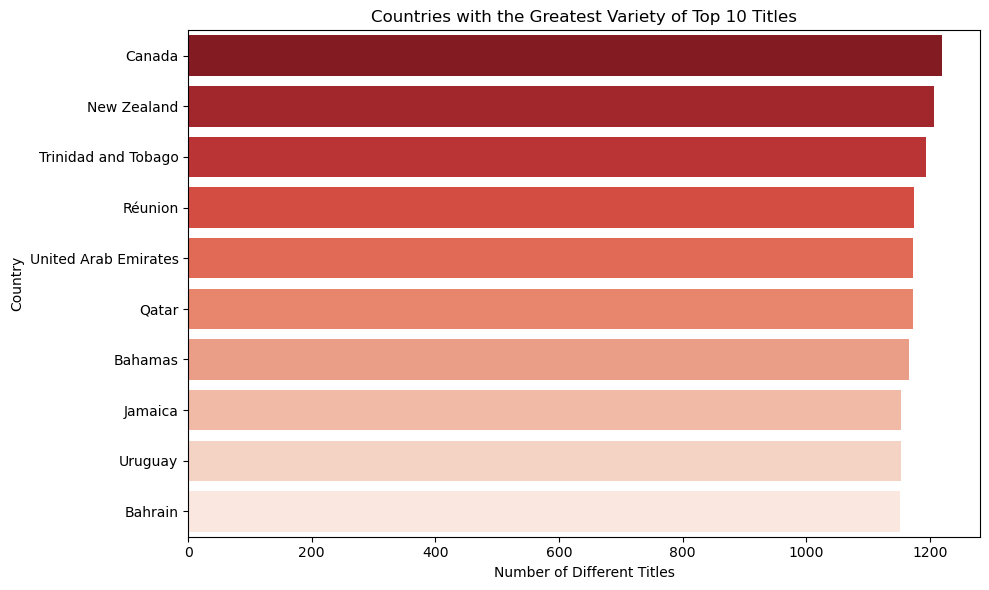

In [10]:
# Count the different titles that reached each country's Top 10 and plot the top 10 countries

top_countries = (df_countries.groupby('country_name')['show_title'].nunique()
                 .sort_values(ascending=False).head(10))

plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index,
            palette="Reds_r", legend=False)

plt.title('Countries with the Greatest Variety of Top 10 Titles')
plt.xlabel('Number of Different Titles')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

## VISUAL 4 - Netflix's Biggest Hits in Their First 91 Days

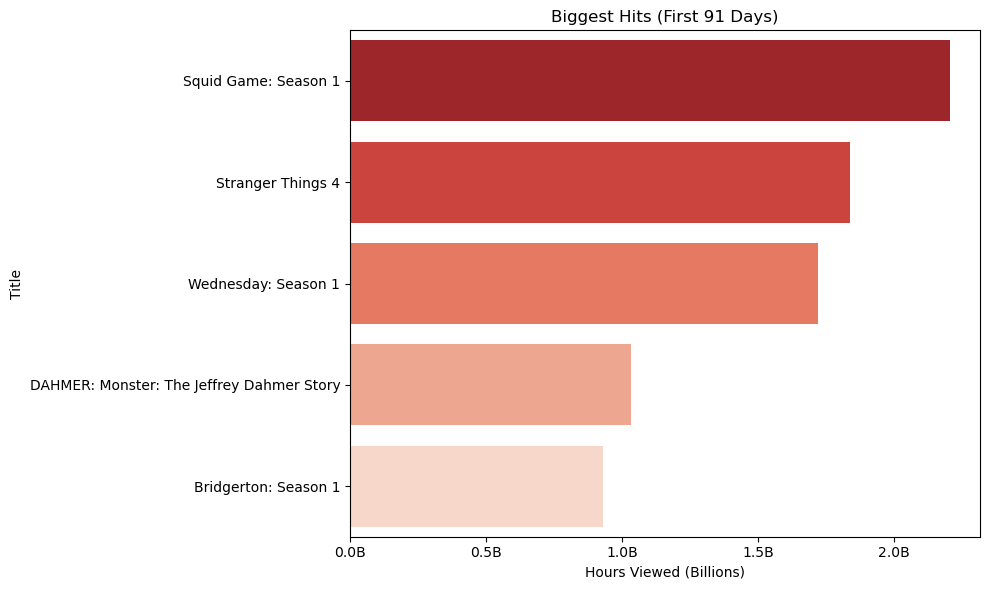

In [11]:
# Plot top 5 by hours in first 91 days (labels by season, largest at top)

dfp = df_popular.copy()

# If a season_title exists and isn't "Movie", use it; otherwise use show_title
labels = np.where(
    dfp["season_title"].notna() & (dfp["season_title"].str.lower() != "movie"),
    dfp["season_title"],
    dfp["show_title"])
dfp = dfp.assign(label=labels)

dfp = dfp.sort_values("hours_viewed_first_91_days", ascending=False).head(5)

plt.figure(figsize=(10, 6))
sns.barplot(data=dfp, x="hours_viewed_first_91_days", y="label", hue="label",
            palette="Reds_r", order=dfp["label"], legend=False)

plt.title("Biggest Hits (First 91 Days)")
plt.xlabel("Hours Viewed (Billions)")
plt.ylabel("Title")
plt.gca().xaxis.set_major_formatter(lambda x, p: f"{x/1e9:.1f}B")
plt.tight_layout()
plt.show()

## VISUAL 5 - Weeks in the Top 10 vs. Total Hours Viewed

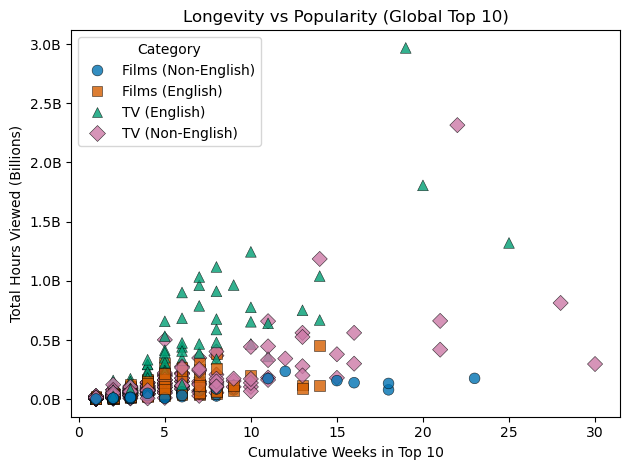

In [12]:
# Show colorblind-safe palette + redundant marker shapes of longevity v popularity - blue, vermilion, green, purple

agg = (df_global.groupby(["show_title", "category"], as_index=False)
             .agg(weeks=("cumulative_weeks_in_top_10", "max"),
                 hours=("weekly_hours_viewed", "sum")))

okabe_ito = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]  

sns.scatterplot(data=agg, x="weeks", y="hours", hue="category",
    style="category", markers=["o","s","^","D"],         # shapes by category - circle, square, triangle, diamond
    palette=okabe_ito, s=60, edgecolor="black", linewidth=0.4, alpha=0.8)

plt.title("Longevity vs Popularity (Global Top 10)")
plt.xlabel("Cumulative Weeks in Top 10")
plt.ylabel("Total Hours Viewed (Billions)")
plt.gca().yaxis.set_major_formatter(lambda x, p: f"{x/1e9:.1f}B")
plt.legend(title="Category", frameon=True)
plt.tight_layout()
plt.show()

## VISUAL 6 - Longest-Running Titles in the Global Top 10

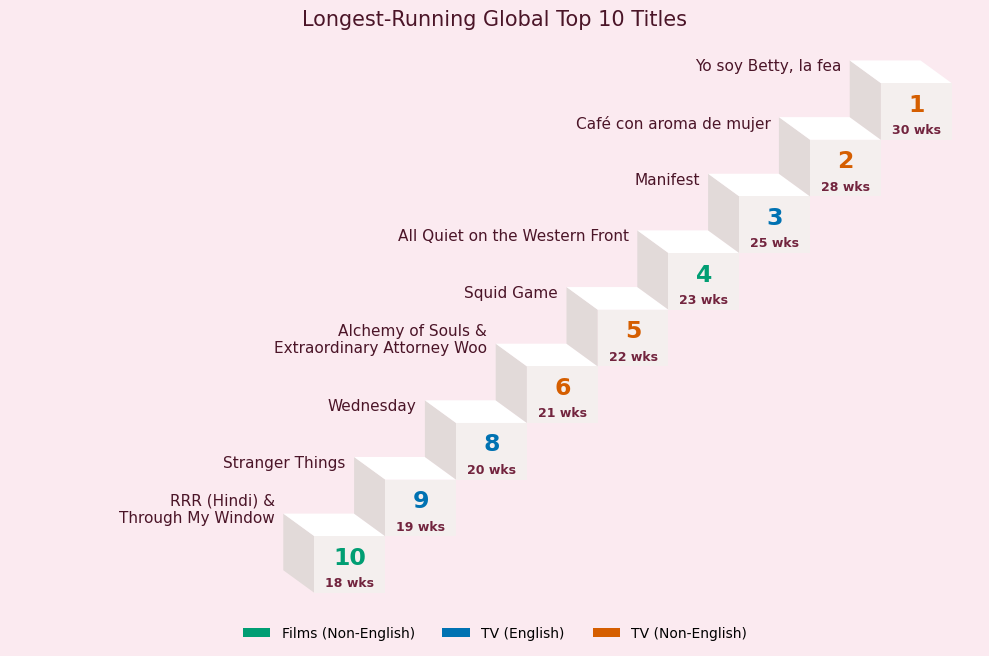

In [13]:
# Show a 3D staircase of the titles with the most weeks in the Global Top 10 (tied titles share a step)

from matplotlib.patches import Polygon, Patch

tw = df_global.groupby("show_title", as_index=False).agg(weeks=("cumulative_weeks_in_top_10", "max"), category=("category", "first")).sort_values("weeks", ascending=False)
top10 = tw[tw["weeks"] >= tw["weeks"].iloc[9]].assign(rank=lambda d: d["weeks"].rank(method="min", ascending=False).astype(int))
steps = top10.groupby("weeks", as_index=False).agg(rank=("rank", "min"), category=("category", lambda x: x.iloc[0] if x.nunique() == 1 else "Mixed categories"), titles=("show_title", list))
colors = {"TV (English)": "#0072B2", "TV (Non-English)": "#D55E00", "Films (English)": "#E69F00", "Films (Non-English)": "#009E73", "Mixed categories": "#666666"}
fig, ax = plt.subplots(figsize=(10, 6.6), facecolor="#FBEAF0")
for i, s in enumerate(steps.itertuples()):
    x, b, t = 215 + i * 50, i * 40, i * 40 + 40
    ax.add_patch(Polygon([(x, b), (x, t), (x - 22, t + 16), (x - 22, b + 16)], facecolor="#E2DAD9"))
    ax.add_patch(Polygon([(x, t), (x + 50, t), (x + 28, t + 16), (x - 22, t + 16)], facecolor="#FFFFFF"))
    ax.add_patch(plt.Rectangle((x, b), 50, 40, facecolor="#F4EFEE"))
    ax.text(x + 25, t - 15, str(s.rank), ha="center", va="center", fontsize=17, fontweight="bold", color=colors[s.category])
    ax.text(x + 25, b + 7, f"{s.weeks} wks", ha="center", va="center", fontsize=9, fontweight="bold", color="#72243E")
    ax.text(x - 28, t + 12 + 7 * (len(s.titles) - 1), " &\n".join(sorted(s.titles)), ha="right", va="center", fontsize=11, color="#4B1528", in_layout=False)
ax.legend(handles=[Patch(facecolor=colors[c], label=c) for c in steps["category"].unique()], loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=steps["category"].nunique(), frameon=False, fontsize=10)
ax.set(facecolor="#FBEAF0", xlim=(0, 215 + len(steps) * 50 + 20), ylim=(-10, len(steps) * 40 + 35), aspect="equal")
ax.axis("off")
plt.title("Longest-Running Global Top 10 Titles", fontsize=15, color="#4B1528")
plt.tight_layout()
plt.show()